# Assessment 3
## III. Data Analysis with Python

**Research question:** Which recorded characteristics are associated with
cardiovascular disease, and how accurately can the disease label be classified?

The analysis uses the 70,000-record SQL export from the database assessments.
It covers exploratory analysis, blood-pressure cleaning, four hypothesis tests,
OLS, seven classifiers and bounded parameter tuning.

**Environment:** local Python. The course brief also requests a Watson Studio
rerun; no Watson Studio execution is included in these results.

### 1. Data and quality checks

Age is stored in days; `AGE_YEARS = AGE / 365.25` is a derived analysis feature.
Gender, cholesterol, glucose and lifestyle indicators are category codes.
`CARDIO` is the binary target; `ID` is excluded from all models.
The SQL export is read without its own synthetic index column.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
from analysis import (ROOT, RESULTS, FIGURES, FEATURES, BloodPressureClipper,
                      model_pipeline, load_data, exploration, hypothesis_tests, classification)

frame, audit = load_data()
display(pd.Series(audit, name='Value').to_frame())
display(frame.head(10))
display(frame.describe().T.round(3))
display(frame.isna().sum().rename('Missing values').to_frame())

,Value
records,70000
original_columns,13
source_sha256,c2f7a922e8cdbc4811ceb5590ffb70858973a76f4710f7...
missing_values,0
duplicate_ids,0
identical_non_id_records,24
disease_cases,34979
disease_fraction,0.4997


,ID,AGE,GENDER,HEIGHT,WEIGHT,AP_HI,AP_LO,CHOLESTEROL,GLUC,SMOKE,ALCO,ACTIVE,CARDIO,AGE_YEARS
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0,50.357290
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1,55.381246
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1,51.627652
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1,48.249144
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0,47.841205
5,8,21914,1,151,67.0,120,80,2,2,0,0,0,0,59.997262
6,9,22113,1,157,93.0,130,80,3,1,0,0,1,0,60.542094
7,12,22584,2,178,95.0,130,90,3,3,0,0,1,1,61.831622
8,13,17668,1,158,71.0,110,70,1,1,0,0,1,0,48.372348
9,14,19834,1,164,68.0,110,60,1,1,0,0,0,0,54.302533


,count,mean,std,min,25%,50%,75%,max
ID,70000.0,49972.420,28851.302,0.000,25006.750,50001.500,74889.25,99999.000
AGE,70000.0,19468.866,2467.252,10798.000,17664.000,19703.000,21327.00,23713.000
GENDER,70000.0,1.350,0.477,1.000,1.000,1.000,2.00,2.000
HEIGHT,70000.0,164.359,8.210,55.000,159.000,165.000,170.00,250.000
WEIGHT,70000.0,74.206,14.396,10.000,65.000,72.000,82.00,200.000
AP_HI,70000.0,128.817,154.011,-150.000,120.000,120.000,140.00,16020.000
AP_LO,70000.0,96.630,188.473,-70.000,80.000,80.000,90.00,11000.000
CHOLESTEROL,70000.0,1.367,0.680,1.000,1.000,1.000,2.00,3.000
GLUC,70000.0,1.226,0.572,1.000,1.000,1.000,1.00,3.000
SMOKE,70000.0,0.088,0.283,0.000,0.000,0.000,0.00,1.000


,Missing values
ID,0
AGE,0
GENDER,0
HEIGHT,0
WEIGHT,0
AP_HI,0
AP_LO,0
CHOLESTEROL,0
GLUC,0
SMOKE,0


There are no missing values or duplicate IDs. Twenty-four records have identical
non-ID values; they are retained because distinct patient IDs do not establish
duplicate patients. The source contains extreme blood-pressure, height and
weight values. All raw records remain available for inspection.

### 2. Exploratory analysis

Pearson correlations and raw distributions describe the supplied data before
cleaning. Correlations involving category codes are exploratory; they do not
establish causation. The scatter plots display a reproducible 3,000-record
sample; trend lines use all records. A straight line against a binary label is
a descriptive trend rather than a calibrated probability model.

,Correlation with CARDIO
AGE_YEARS,0.238159
CHOLESTEROL,0.221147
WEIGHT,0.181660
GLUC,0.089307
AP_LO,0.065719
AP_HI,0.054475
GENDER,0.008109
ALCO,-0.007330
HEIGHT,-0.010821
SMOKE,-0.015486


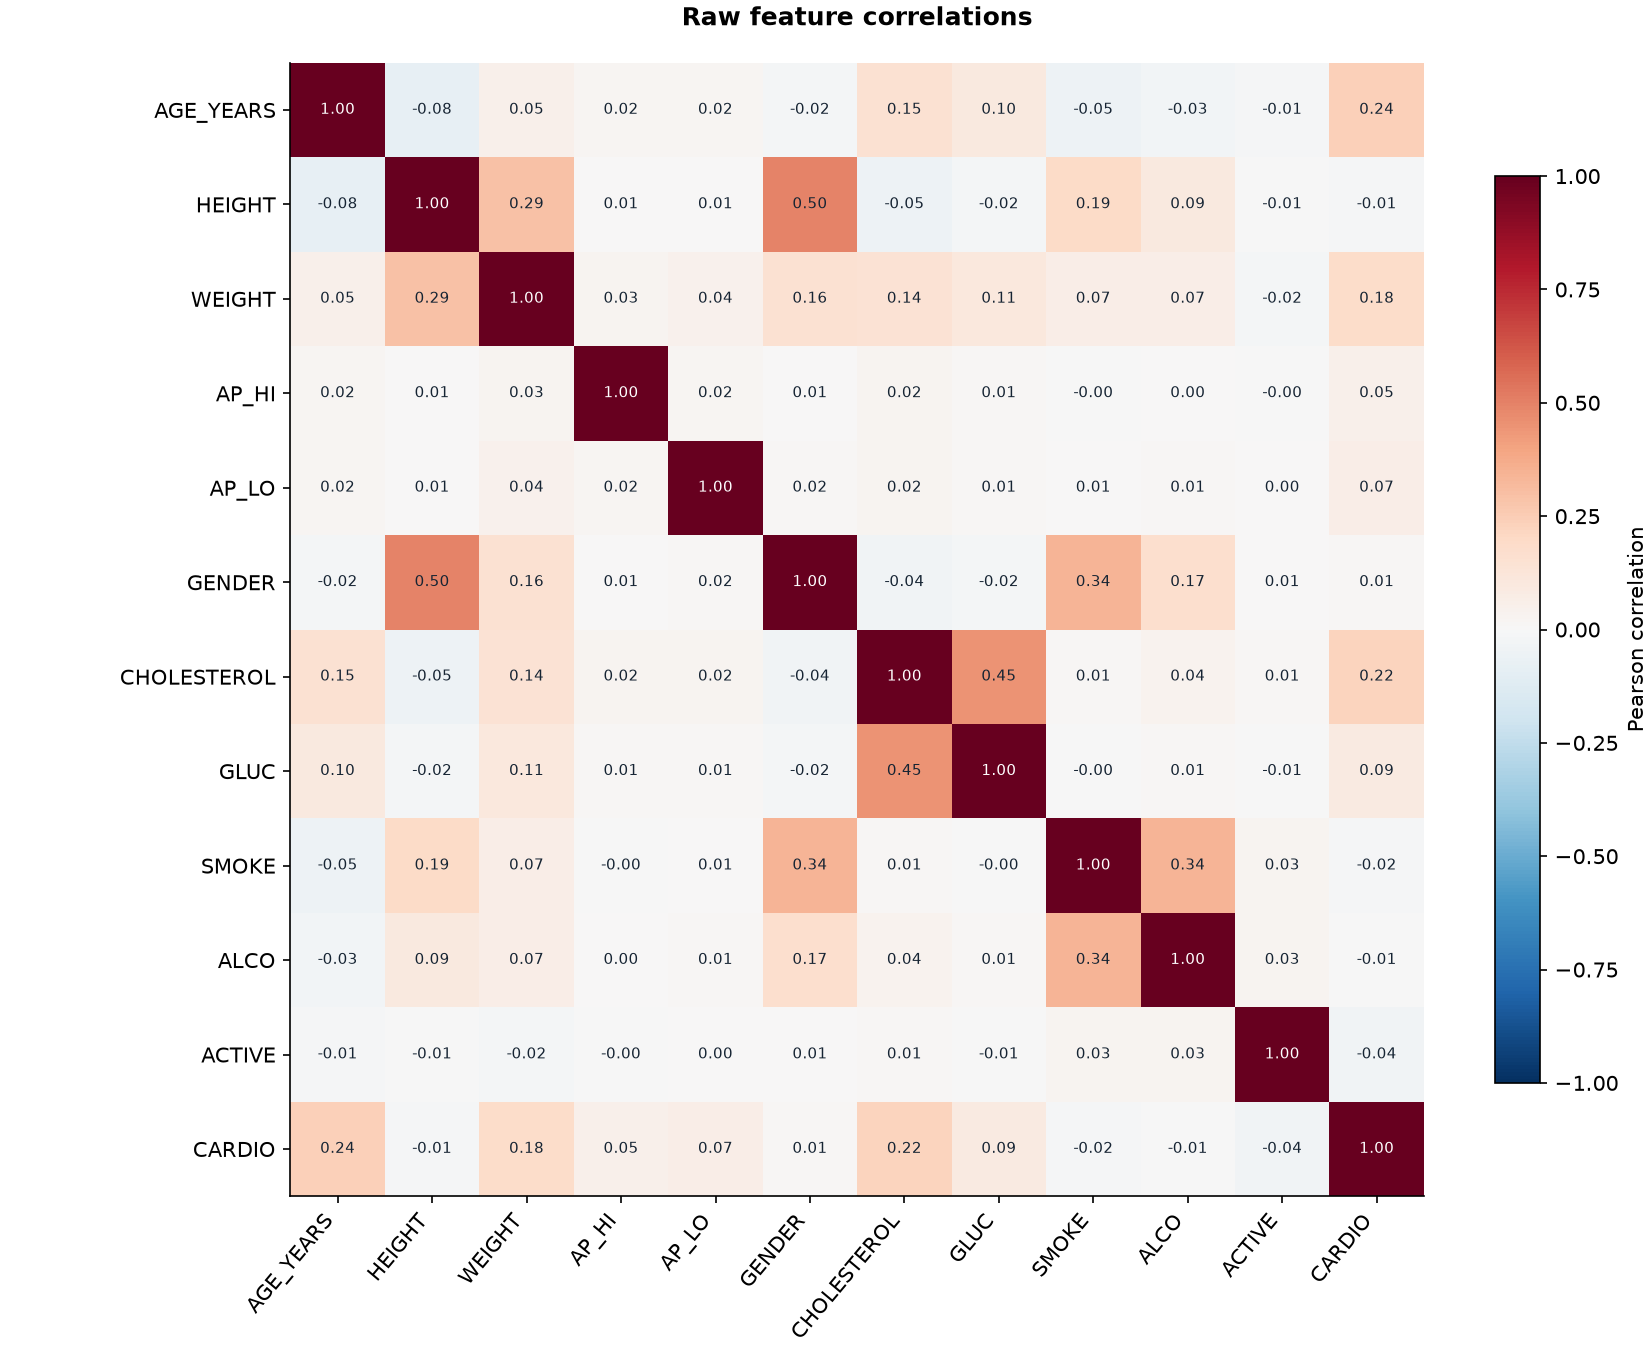

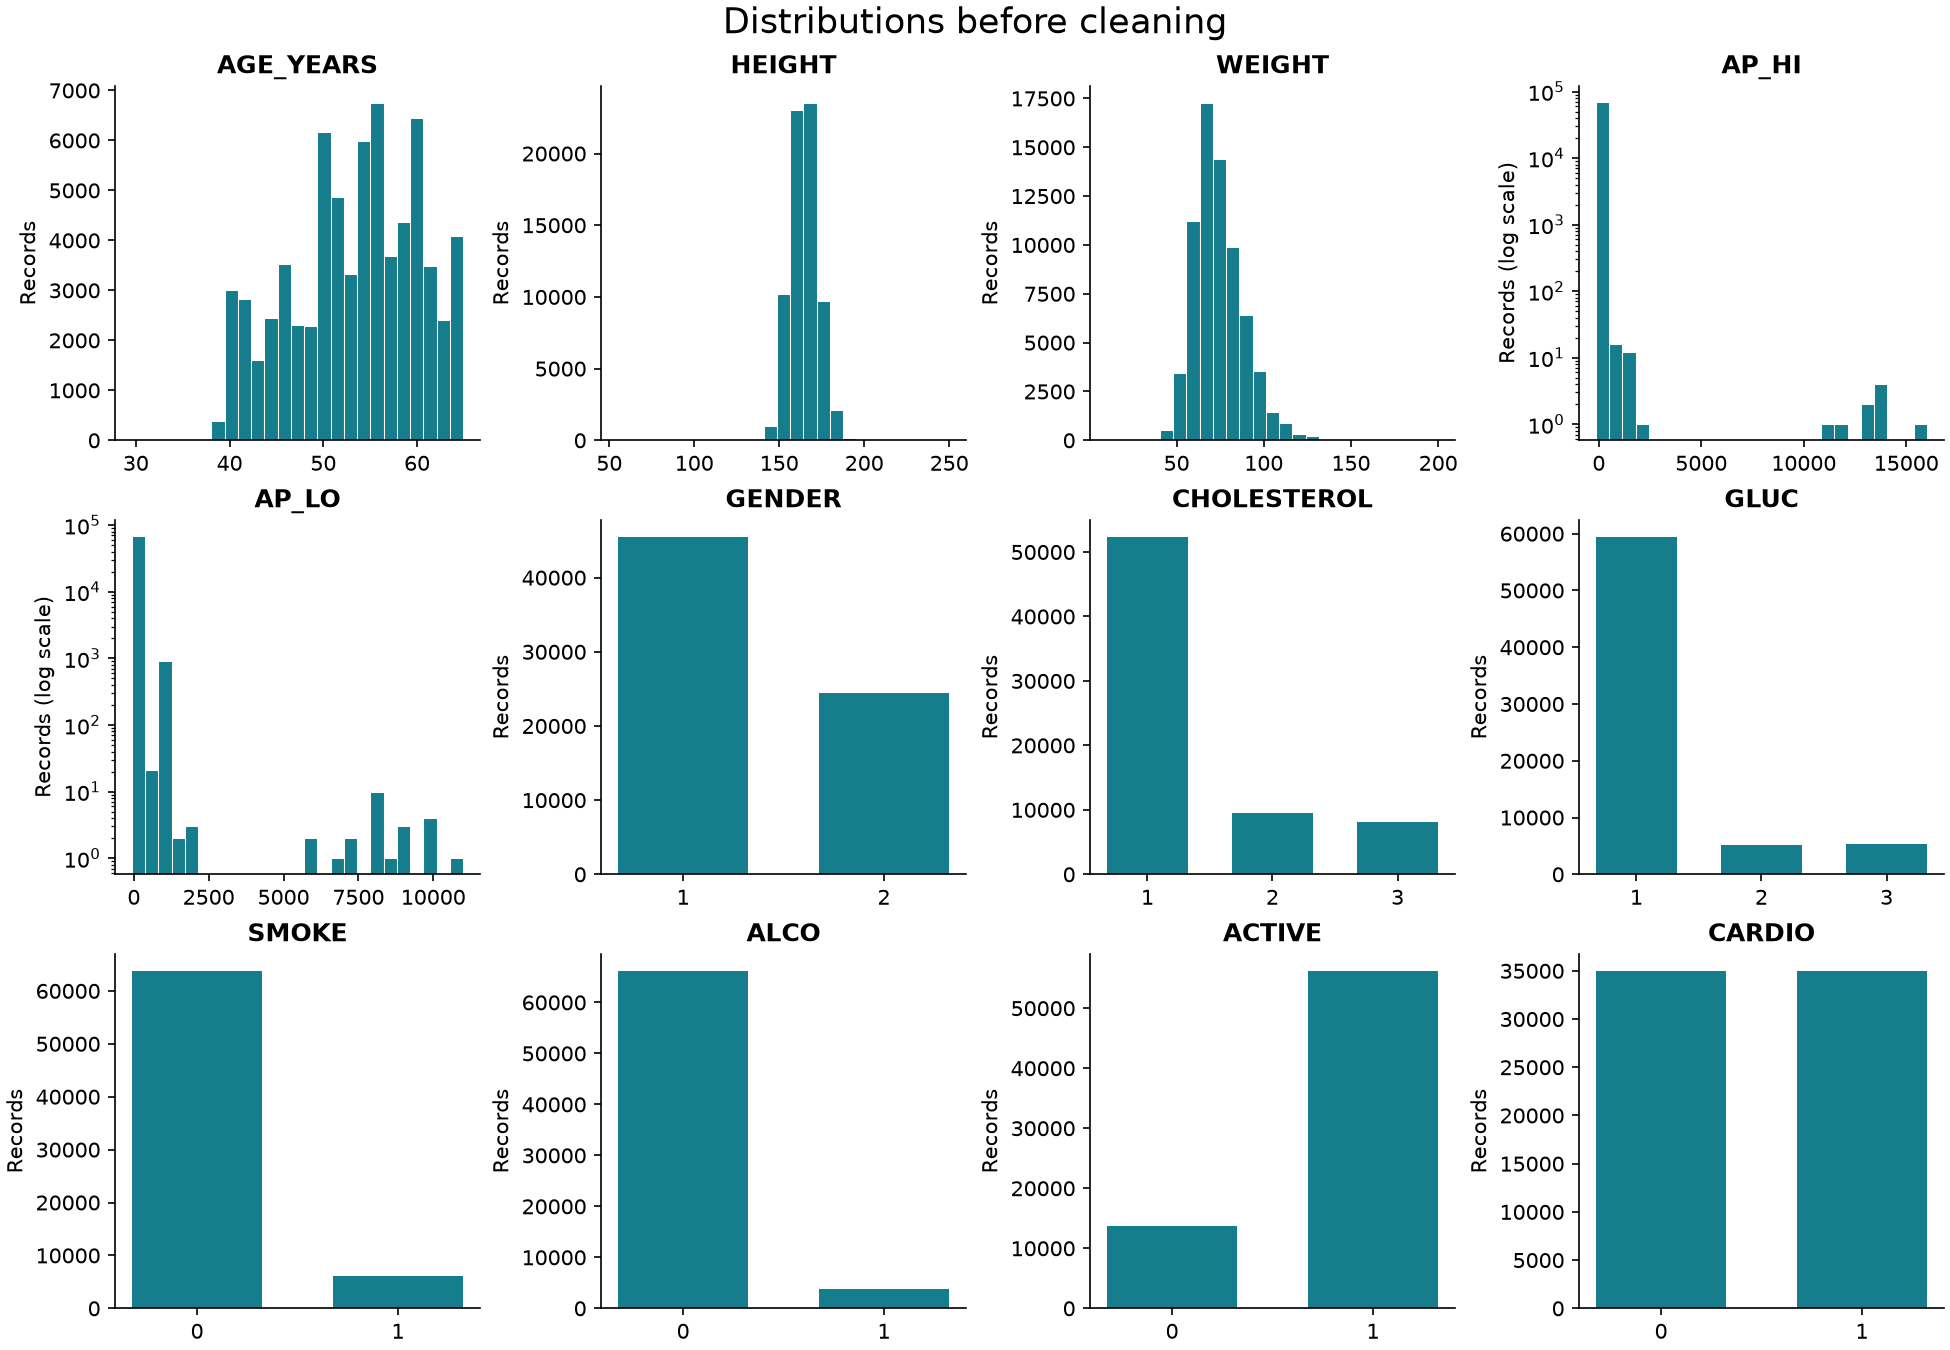

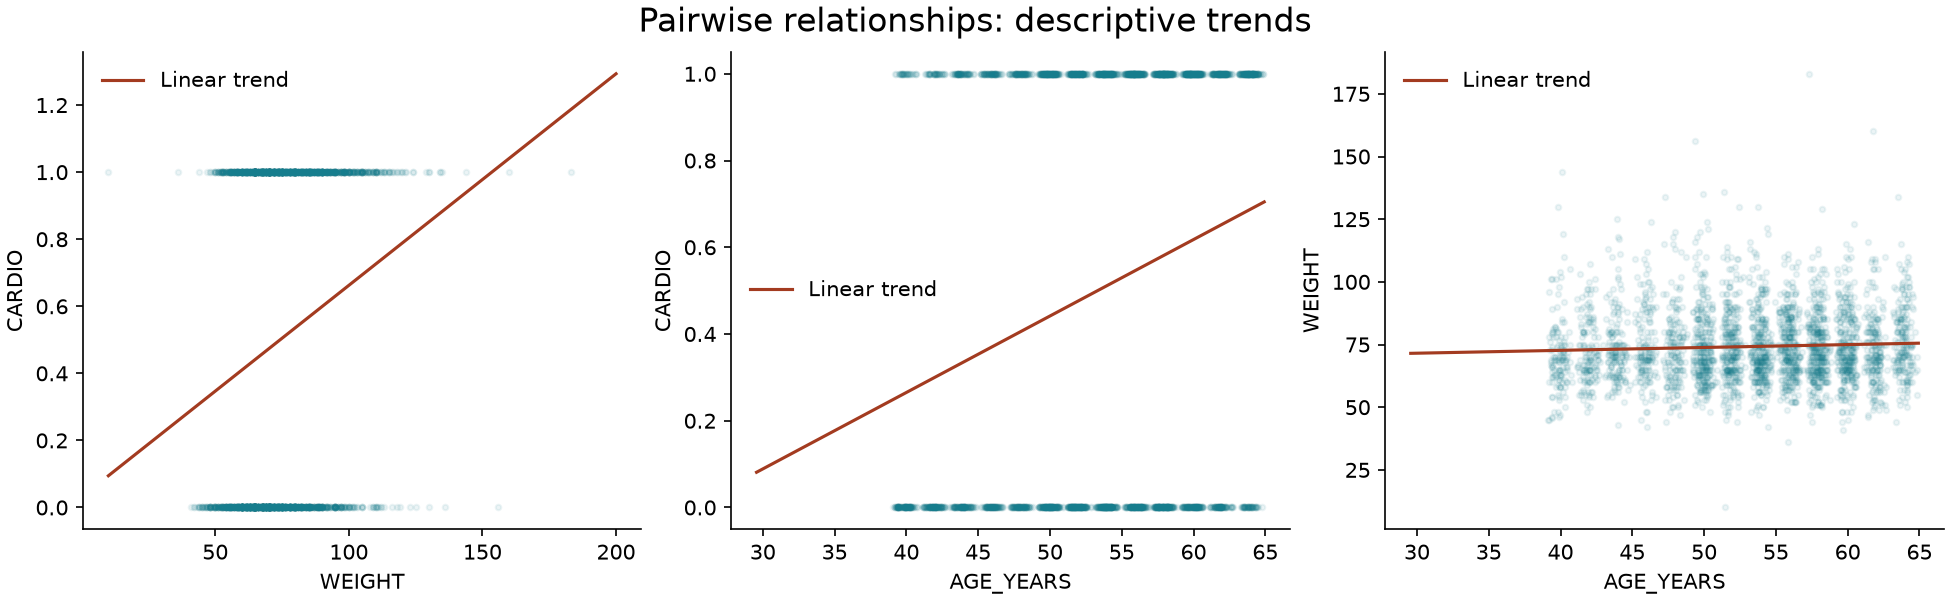

In [2]:
correlation, clipping, descriptive = exploration(frame)
display(correlation['CARDIO'].drop('CARDIO').sort_values(ascending=False).rename('Correlation with CARDIO').to_frame())
display(Image(filename=str(FIGURES / 'correlation_matrix.png')))
display(Image(filename=str(FIGURES / 'distributions.png')))
display(Image(filename=str(FIGURES / 'relationships.png')))

### 3. Blood-pressure cleaning and standardization

For each pressure variable, values outside `[Q1 - 1.5 IQR, Q3 + 1.5 IQR]` are
clipped to those limits. This follows the brief's outlier treatment. It retains
all records, although it cannot establish the correct clinical measurement.

The following limits use the full dataset **only for descriptive plots and
statistical analysis**. Classification pipelines independently learn their
limits, numeric means and scales on each training partition. Numeric predictors
are standardized; categorical predictors are one-hot encoded.

,lower,upper,values_clipped
AP_HI,90.0,170.0,1435
AP_LO,65.0,105.0,4632


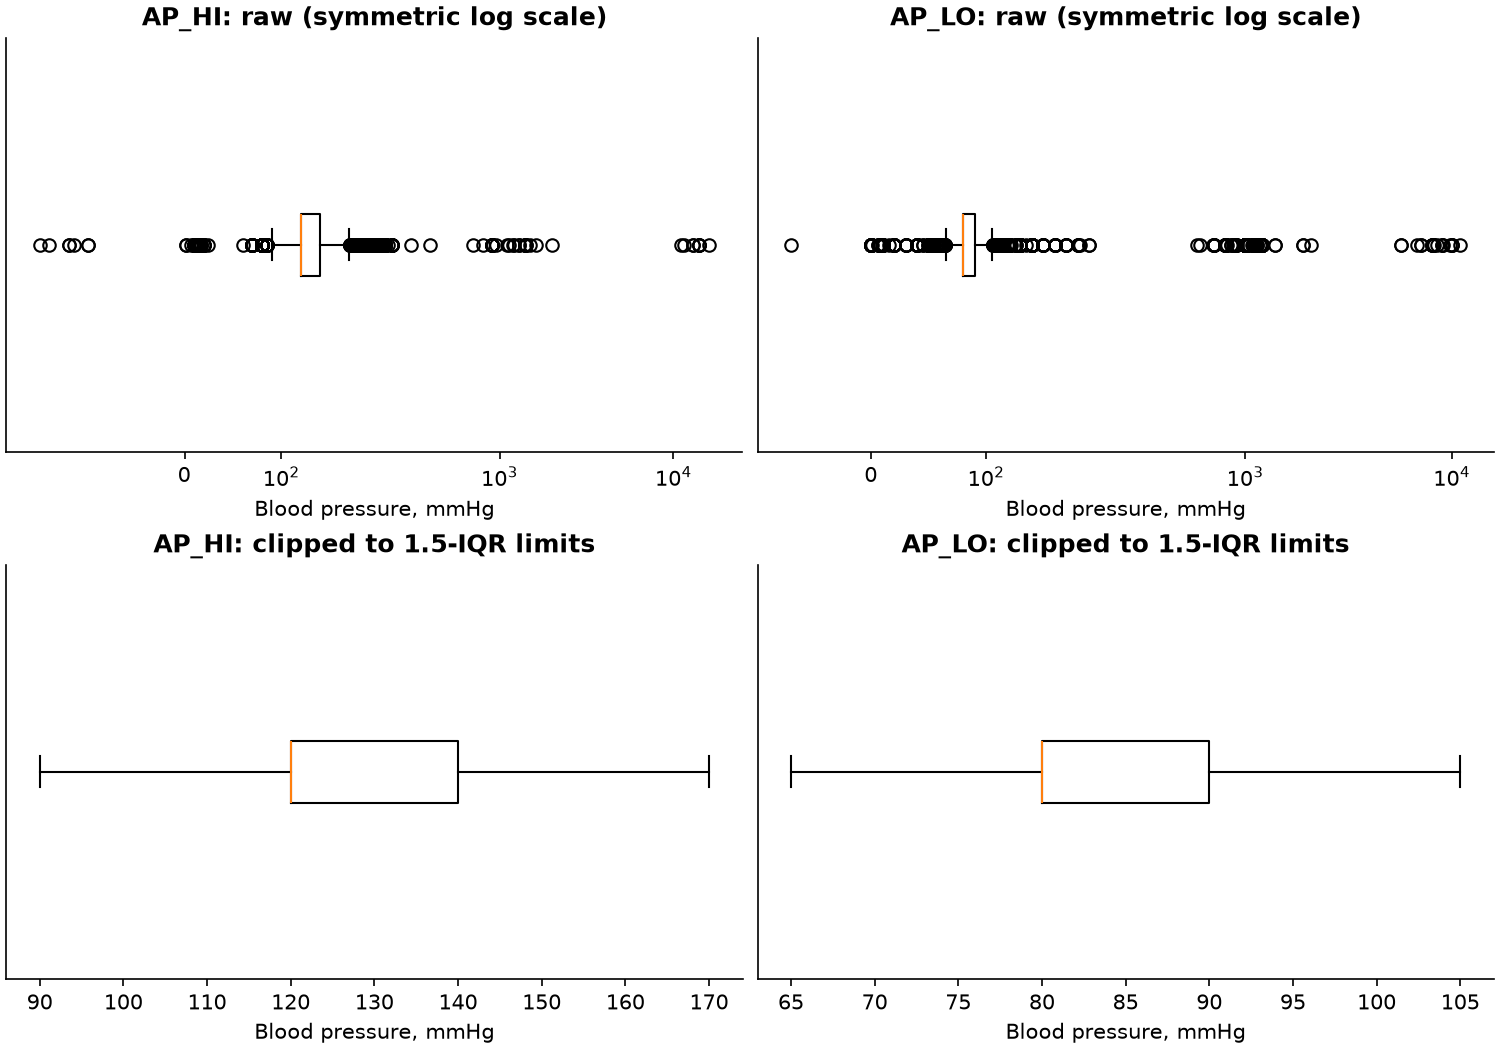

class BloodPressureClipper(TransformerMixin, BaseEstimator):
    """Learn the 1.5-IQR limits from the current training partition."""
    def fit(self, X, y=None):
        quartiles = X[['AP_HI', 'AP_LO']].quantile([0.25, 0.75])
        width = quartiles.loc[0.75] - quartiles.loc[0.25]
        self.lower_ = quartiles.loc[0.25] - 1.5 * width
        self.upper_ = quartiles.loc[0.75] + 1.5 * width
        return self

    def transform(self, X):
        check_is_fitted(self, 'lower_')
        result = X.copy()
        result[['AP_HI', 'AP_LO']] = result[['AP_HI', 'AP_LO']].clip(
            self.lower_, self.upper_, axis=1)
        return result

def model_pipeline(estimator):
    return Pipeline([
        ('blood_pressure', BloodPressureClipper()),
        ('features', ColumnTransformer([
            ('numeric', StandardScaler(), NUMERIC),
            ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAL),
        ])),
        ('model', estimator),
    

In [3]:
display(clipping)
display(Image(filename=str(FIGURES / 'blood_pressure_cleaning.png')))
from inspect import getsource
print(getsource(BloodPressureClipper))
print(getsource(model_pipeline))

### 4. Hypothesis tests

Four null hypotheses are assessed at 0.05: disease prevalence is equal across
cholesterol categories; prevalence is equal above and below mean age; weight
has zero Pearson association with the binary target; alcohol status and disease
status are independent. The age comparison uses Welch's t-test. ANOVA and
Pearson correlation reproduce the brief's requested analyses; binary outcomes
and observational sampling limit their interpretation.

Holm adjustment controls the family-wise error rate across these four tests.
Effect measures are reported alongside p-values. A non-significant result does
not demonstrate absence of association; a significant result does not establish
a cause. Very small p-values can underflow numerically and are displayed as a bound.

In [4]:
tests, ols = hypothesis_tests(descriptive)
table = tests.copy()
for column in ['p_value', 'p_holm']:
    table[column] = table[column].map(lambda x: '< 1e-300' if x < 1e-300 else f'{x:.4g}')
display(table)
for _, row in tests.iterrows():
    decision = 'Reject' if row.reject_at_0_05 else 'Do not reject'
    print(f'{row.variable}: {decision} the null hypothesis after Holm adjustment.')
display(pd.Series(json.loads((RESULTS / 'age_test_groups.json').read_text()), name='Value').to_frame())

,variable,test,statistic,p_value,effect,effect_measure,p_holm,reject_at_0_05
0,CHOLESTEROL,One-way ANOVA,1799.660786,< 1e-300,0.325328,Range of disease proportions,< 1e-300,True
1,AGE_YEARS,Welch t-test: older vs younger than mean,52.445920,< 1e-300,0.195253,Difference in disease proportions,< 1e-300,True
2,WEIGHT,Pearson correlation,0.181660,< 1e-300,0.181660,Pearson r,< 1e-300,True
3,ALCO,Chi-square with Yates correction,3.696547,0.05453,0.007267,Cramers V,0.05453,False


CHOLESTEROL: Reject the null hypothesis after Holm adjustment.
AGE_YEARS: Reject the null hypothesis after Holm adjustment.
WEIGHT: Reject the null hypothesis after Holm adjustment.
ALCO: Do not reject the null hypothesis after Holm adjustment.


,Value
cutoff_years,5.330285e+01
younger_n,3.154000e+04
older_n,3.846000e+04
younger_disease_fraction,3.924223e-01
older_disease_fraction,5.876755e-01
levene_p_value,9.244306e-08


### 5. OLS explanatory model

OLS relates `CARDIO` to the five numeric predictors and six categorical
predictors. Categorical variables use reference coding. HC3 standard errors
account for heteroskedasticity. With a binary dependent variable this is a
linear probability model: predictions may fall outside [0, 1], so OLS is used
for the requested explanatory exercise rather than the final classifier.
Coefficients describe adjusted associations, not causal effects.

In [5]:
print(ols.summary().as_text())
display(pd.read_csv(RESULTS / 'ols_coefficients.csv', index_col=0))

                            OLS Regression Results                            
Dep. Variable:                 CARDIO   R-squared:                       0.235
Model:                            OLS   Adj. R-squared:                  0.235
Method:                 Least Squares   F-statistic:                     2117.
Date:                Fri, 06 Nov 2026   Prob (F-statistic):               0.00
Time:                        02:34:02   Log-Likelihood:                -41420.
No. Observations:               70000   AIC:                         8.287e+04
Df Residuals:                   69986   BIC:                         8.300e+04
Df Model:                          13                                         
Covariance Type:                  HC3                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept              -1.6058    

,coefficient,robust_std_error,p_value,ci_lower,ci_upper
Intercept,-1.605807,0.042841,1.758745e-307,-1.689774,-1.521840
C(GENDER)[T.2],-0.004251,0.004245,3.166169e-01,-0.012570,0.004069
C(CHOLESTEROL)[T.2],0.078433,0.005172,6.006192e-52,0.068297,0.088570
C(CHOLESTEROL)[T.3],0.198501,0.005979,1.095686e-241,0.186783,0.210220
C(GLUC)[T.2],0.000141,0.006781,9.834547e-01,-0.013151,0.013432
C(GLUC)[T.3],-0.054505,0.007352,1.227746e-13,-0.068914,-0.040095
C(SMOKE)[T.1],-0.025656,0.006377,5.742256e-05,-0.038154,-0.013157
C(ALCO)[T.1],-0.037954,0.007625,6.442847e-07,-0.052900,-0.023009
C(ACTIVE)[T.1],-0.043770,0.004230,4.311161e-25,-0.052061,-0.035479
AGE_YEARS,0.010145,0.000249,0.000000e+00,0.009656,0.010634


### 6. Classification design

A stratified split reserves 30% of the records as the final test set, using
random seed 42. The remaining 70% is divided into 39,200 fitting records and
9,800 validation records. The final model is selected by validation ROC AUC,
with accuracy and model name as deterministic tie breakers, then refitted on
all 49,000 non-test records. The test set is evaluated once after selection.

Ridge, random forest, gradient boosting, AdaBoost, bagging, extra trees and
stacking are compared. Three additional gradient-boosting settings provide a
bounded tuning exercise. Stacking uses three stratified internal folds, with
preprocessing inside each base estimator so its fold statistics stay separate.
Numeric gender/category codes are not interpreted as continuous measurements.
No patient ID, target column or test-set statistic enters a fitted feature pipeline.

Ridge: validation accuracy 0.7288; ROC AUC 0.7898


Random forest: validation accuracy 0.7327; ROC AUC 0.7979


Gradient boosting: validation accuracy 0.7363; ROC AUC 0.7985


AdaBoost: validation accuracy 0.7263; ROC AUC 0.7929


Bagging: validation accuracy 0.7166; ROC AUC 0.7765


Extra trees: validation accuracy 0.7318; ROC AUC 0.7941


... (2 outputs left out)

Boosting: 160 trees, depth 3, rate 0.05: validation accuracy 0.7349; ROC AUC 0.7996


Boosting: 100 trees, depth 3, rate 0.1: validation accuracy 0.7349; ROC AUC 0.7995


,model,stage,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision,fit_seconds
8,"Boosting: 160 trees, depth 3, rate 0.05",tuned,0.7349,0.7349,0.7524,0.6998,0.7251,0.7996,0.7867,4.0884
9,"Boosting: 100 trees, depth 3, rate 0.1",tuned,0.7349,0.7349,0.7529,0.6988,0.7248,0.7995,0.7844,2.5911
6,Stacking,comparison,0.7340,0.7340,0.7535,0.6949,0.7230,0.7986,0.7836,5.4449
2,Gradient boosting,comparison,0.7363,0.7363,0.7528,0.7033,0.7272,0.7985,0.7841,1.7661
7,"Boosting: 160 trees, depth 2, rate 0.05",tuned,0.7352,0.7352,0.7524,0.7006,0.7256,0.7981,0.7839,2.9774
1,Random forest,comparison,0.7327,0.7326,0.7596,0.6802,0.7177,0.7979,0.7816,0.8063
5,Extra trees,comparison,0.7318,0.7318,0.7666,0.6661,0.7128,0.7941,0.7796,0.6825
3,AdaBoost,comparison,0.7263,0.7263,0.7697,0.6455,0.7021,0.7929,0.7750,1.1944
0,Ridge,comparison,0.7288,0.7287,0.7610,0.6665,0.7106,0.7898,0.7759,0.0540
4,Bagging,comparison,0.7166,0.7166,0.7679,0.6204,0.6863,0.7765,0.7445,1.5590


,records,disease_fraction
split,,
test,21000,0.499714
train,39200,0.499694
validation,9800,0.499694


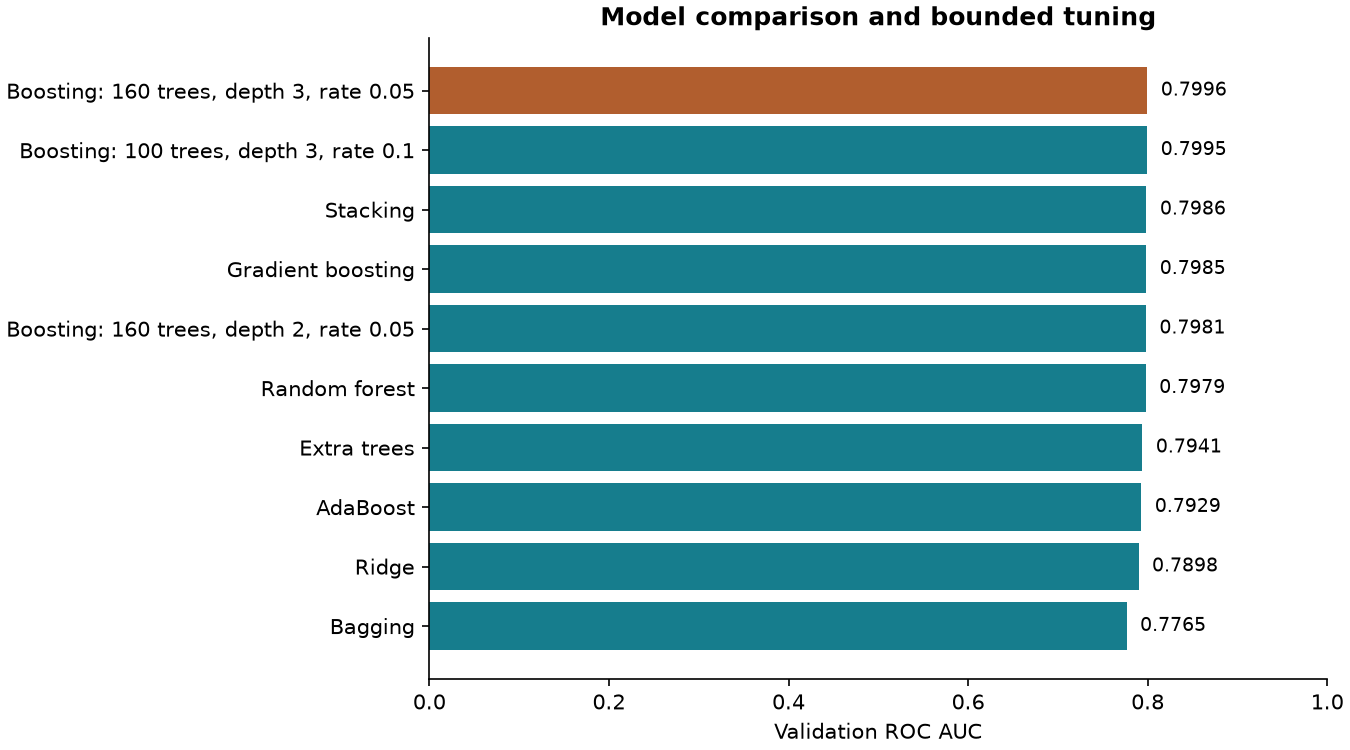

In [6]:
comparison, test_metrics, selected_name = classification(frame)
display(comparison.round(4))
display(pd.read_csv(RESULTS / 'split_assignments.csv').groupby('split').agg(records=('ID', 'size'), disease_fraction=('CARDIO', 'mean')))
display(Image(filename=str(FIGURES / 'model_comparison.png')))

### 7. Held-out evaluation

Accuracy is accompanied by precision, recall, F1, balanced accuracy, ROC AUC
and average precision. The accuracy interval uses the Wilson method. The
majority-class baseline provides a reference. The confusion matrix shows both
false positives and false negatives; accuracy alone does not describe those costs.

Selected model: Boosting: 160 trees, depth 3, rate 0.05
Final training records: 49000
Held-out records: 21000
Majority-class baseline accuracy: 0.5003


,Test result
accuracy,0.7320
balanced_accuracy,0.7320
precision,0.7483
recall,0.6989
f1,0.7227
roc_auc,0.7990
average_precision,0.7816
accuracy_ci_lower,0.7260
accuracy_ci_upper,0.7380


,precision,recall,f1-score,support
0,0.7178,0.7652,0.7408,10506.000
1,0.7483,0.6989,0.7227,10494.000
accuracy,0.7320,0.7320,0.7320,0.732
macro avg,0.7331,0.7320,0.7317,21000.000
weighted avg,0.7331,0.7320,0.7318,21000.000


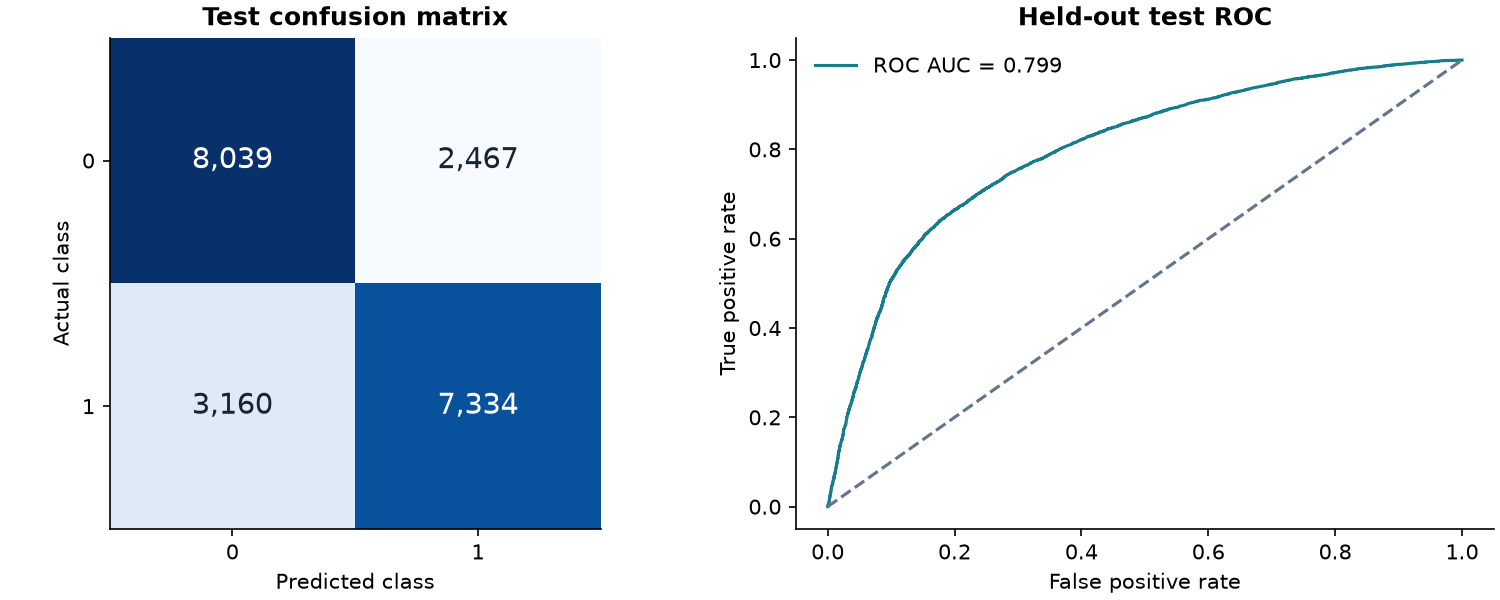

In [7]:
summary = json.loads((RESULTS / 'model_summary.json').read_text())
print('Selected model:', selected_name)
print('Final training records:', summary['final_training_records'])
print('Held-out records:', summary['test_records'])
print('Majority-class baseline accuracy:', f"{summary['majority_baseline_test_accuracy']:.4f}")
display(pd.Series(test_metrics, name='Test result').to_frame().round(4))
display(pd.DataFrame(json.loads((RESULTS / 'classification_report.json').read_text())).T.round(4))
display(Image(filename=str(FIGURES / 'test_evaluation.png')))

### 8. Findings and limitations

In [8]:
display(Markdown(
    f"**{selected_name}** achieved **{test_metrics['accuracy']:.2%} accuracy** "
    f"on 21,000 held-out records (95% interval "
    f"{test_metrics['accuracy_ci_lower']:.2%}-{test_metrics['accuracy_ci_upper']:.2%}), "
    f"with ROC AUC **{test_metrics['roc_auc']:.3f}** and recall **{test_metrics['recall']:.2%}**."
))

**Boosting: 160 trees, depth 3, rate 0.05** achieved **73.20% accuracy** on 21,000 held-out records (95% interval 72.60%-73.80%), with ROC AUC **0.799** and recall **69.89%**.

The results describe this dataset and this fixed split. Outlier clipping is a
reproducible treatment, not a correction of the original measurements. Distinct
IDs do not prove independent sampling, and the available data do not establish
geographical or temporal representativeness. Identical predictor patterns can
occur across partitions. Repeated holdouts, external validation, calibration
and a clinically justified decision threshold would be needed before practical
use. The model is an academic classification exercise, not a diagnostic tool.

The test set was reserved from parameter selection. Validation scores still
reflect selection among ten candidates and should not be read as external
generalization estimates. The original raw data and all per-record test
predictions are retained for review.

### Reproduction

Install the root `requirements.txt`, open this notebook from `Assessment_3/`
and select **Run All**. The analysis functions are in `analysis.py`.
`python verify_results.py` checks the saved splits, source labels, selected
model, test metrics, clipping limits and notebook outputs without retraining.

References: supplied ADY201m brief, section III;
[dataset description](https://www.kaggle.com/datasets/sulianova/cardiovascular-disease-dataset);
[scikit-learn: preventing data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage);
[SciPy statistical functions](https://docs.scipy.org/doc/scipy/reference/stats.html);
[statsmodels OLS](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.OLS.html).